# PROYECTO DE APLICACIÓN

## LECTURA DE DATOS

In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import scipy.stats



C:\Users\carte\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
df = pd.read_csv("base.csv")
# df = pd.read_csv("base.csv").sample(frac=.1) # para utilizar una muestra

In [3]:
#numero de filas y columnas
df.shape

(1000000, 32)

In [4]:
#numero de 1s y 0s de fraud_bool
df['fraud_bool'].value_counts(normalize=True)

fraud_bool
0    0.988971
1    0.011029
Name: proportion, dtype: float64

## TRATAMIENTO DE NULOS Y DUPLICADOS

### Nulos

In [5]:
#calculamos los nulos en porcentaje
df.isna().mean()*100

fraud_bool                           0.0000
income                               0.0000
name_email_similarity                0.0000
prev_address_months_count           71.2920
current_address_months_count         0.4254
customer_age                         0.0000
days_since_request                   0.0000
intended_balcon_amount               0.0000
payment_type                         0.0000
zip_count_4w                         0.0000
velocity_6h                          0.0000
velocity_24h                         0.0000
velocity_4w                          0.0000
bank_branch_count_8w                 0.0000
date_of_birth_distinct_emails_4w     0.0000
employment_status                    0.0000
credit_risk_score                   16.6771
email_is_free                        0.3038
housing_status                       0.0000
phone_home_valid                     0.0000
phone_mobile_valid                   0.0000
bank_months_count                   25.3635
has_other_cards                 

In [6]:
#eliminamos la variable prev_address_months_count ya que hay demasiados nulos
df = df.drop(columns=['prev_address_months_count'])

In [7]:
#imputamos por la mediana los nulos de variables numéricas
df['bank_months_count'] = df['bank_months_count'].fillna(df['bank_months_count'].median())
df['credit_risk_score'] = df['credit_risk_score'].fillna(df['credit_risk_score'].median())
df['current_address_months_count'] = df['current_address_months_count'].fillna(df['current_address_months_count'].median())
df['session_length_in_minutes'] = df['session_length_in_minutes'].fillna(df['session_length_in_minutes'].median())

#imputamos por la moda el nulo de la variable categórica
#se podría eliminar directamente, pero el impacto es mínimo y se preservan datos.
df['email_is_free'] = df['email_is_free'].fillna(df['email_is_free'].mode()[0])

In [8]:
df.isna().mean()*100

fraud_bool                          0.0
income                              0.0
name_email_similarity               0.0
current_address_months_count        0.0
customer_age                        0.0
days_since_request                  0.0
intended_balcon_amount              0.0
payment_type                        0.0
zip_count_4w                        0.0
velocity_6h                         0.0
velocity_24h                        0.0
velocity_4w                         0.0
bank_branch_count_8w                0.0
date_of_birth_distinct_emails_4w    0.0
employment_status                   0.0
credit_risk_score                   0.0
email_is_free                       0.0
housing_status                      0.0
phone_home_valid                    0.0
phone_mobile_valid                  0.0
bank_months_count                   0.0
has_other_cards                     0.0
proposed_credit_limit               0.0
foreign_request                     0.0
source                              0.0


### Duplicados

In [9]:
#identificamos duplicados
df.duplicated().sum()

np.int64(0)

Se han identificado varias variables con valores nulos en el dataset. La variable prev_address_months_count presenta un porcentaje muy elevado de datos faltantes, por lo que se ha optado por eliminarla.

Para las variables numéricas (bank_months_count, credit_risk_score, current_address_months_count y session_length_in_minutes), se ha aplicado una imputación mediante la mediana, ya que es una medida robusta frente a valores extremos. En el caso de la variable categórica email_is_free, se ha optado por una imputación media la moda. Se han imputado las variables con un porcentaje muy bajo de nulos porque la cantidad de datos faltantes es insignificante y eliminarlos supondría perder información útil sin impacto real en la calidad del dataset. Además, la imputación permite mantener el mayor número de registros posible para el análisis.

Con respecto a los duplicados, no se ha encontrado ninguno.

Tras este proceso, el dataset queda libre de valores nulos y preparado para el análisis exploratorio.

## ANÁLISIS UNIVARIANTE

### Variables numéricas

In [10]:
df.dtypes

fraud_bool                            int64
income                              float64
name_email_similarity               float64
current_address_months_count        float64
customer_age                          int64
days_since_request                  float64
intended_balcon_amount              float64
payment_type                            str
zip_count_4w                          int64
velocity_6h                         float64
velocity_24h                        float64
velocity_4w                         float64
bank_branch_count_8w                  int64
date_of_birth_distinct_emails_4w      int64
employment_status                       str
credit_risk_score                   float64
email_is_free                       float64
housing_status                          str
phone_home_valid                      int64
phone_mobile_valid                    int64
bank_months_count                   float64
has_other_cards                       int64
proposed_credit_limit           

In [11]:
#variables numéricas
numerical_columns = df.select_dtypes(include='number').columns

# Detectar variables binarias
binary_columns = [col for col in numerical_columns if df[col].nunique() == 2]

# Numéricas reales quitando binarias
numerical_columns = [col for col in numerical_columns if col not in binary_columns]
numerical_columns

['income',
 'name_email_similarity',
 'current_address_months_count',
 'customer_age',
 'days_since_request',
 'intended_balcon_amount',
 'zip_count_4w',
 'velocity_6h',
 'velocity_24h',
 'velocity_4w',
 'bank_branch_count_8w',
 'date_of_birth_distinct_emails_4w',
 'credit_risk_score',
 'bank_months_count',
 'proposed_credit_limit',
 'session_length_in_minutes',
 'device_distinct_emails_8w',
 'device_fraud_count',
 'month']

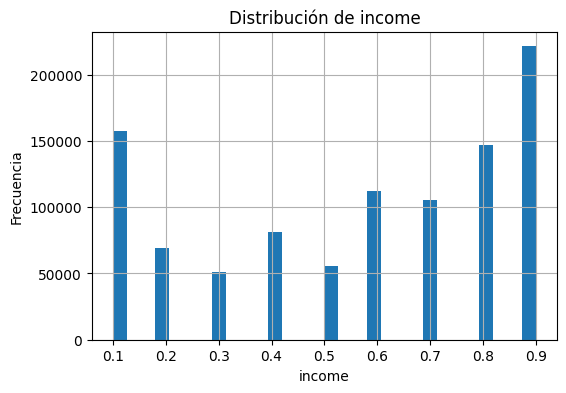

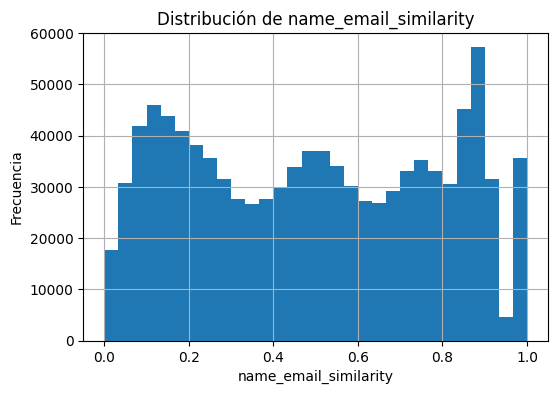

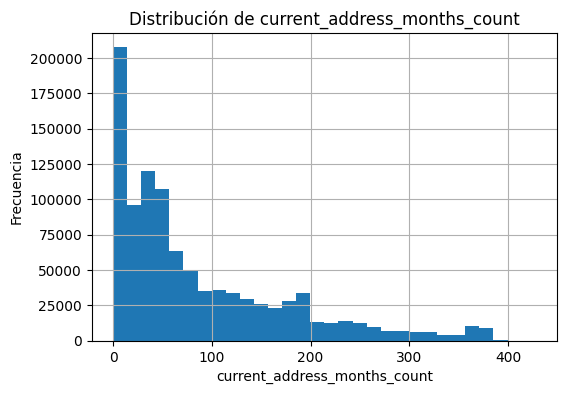

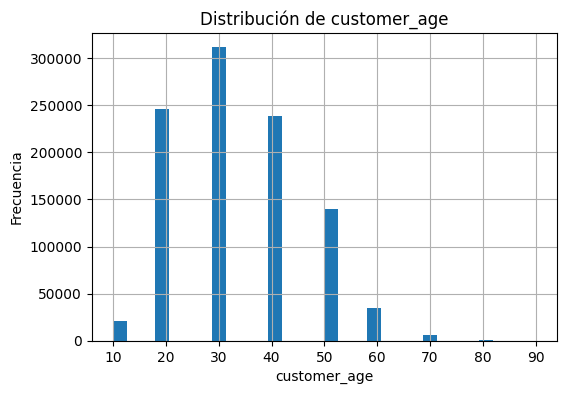

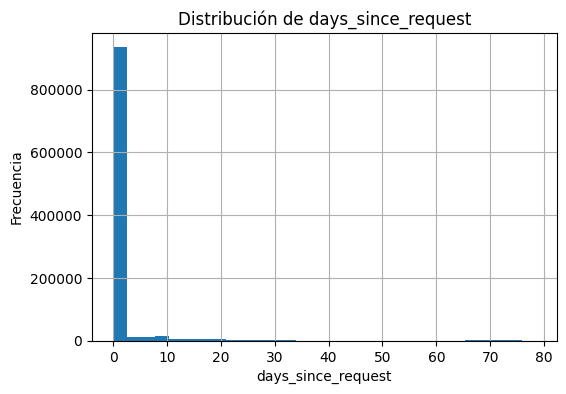

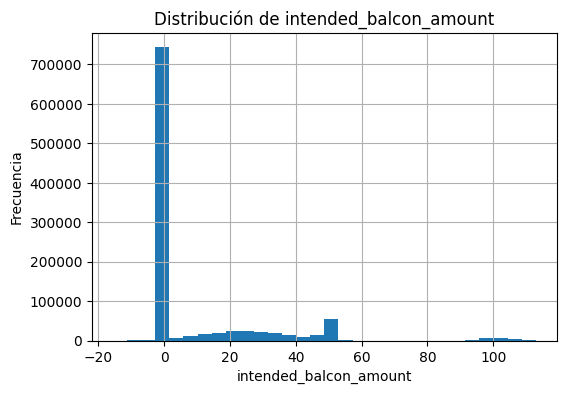

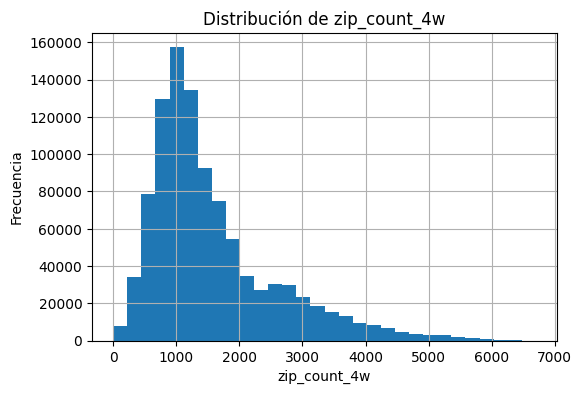

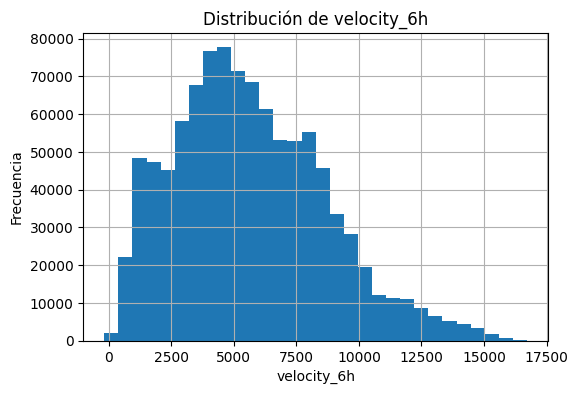

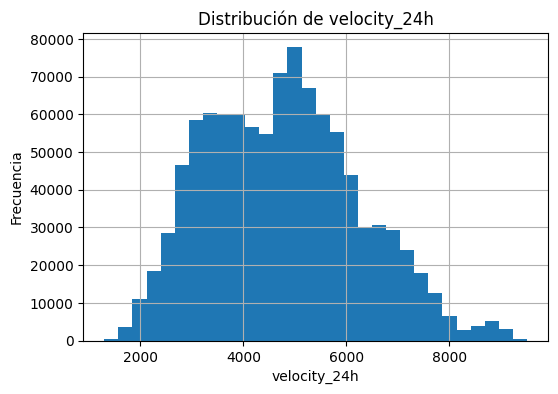

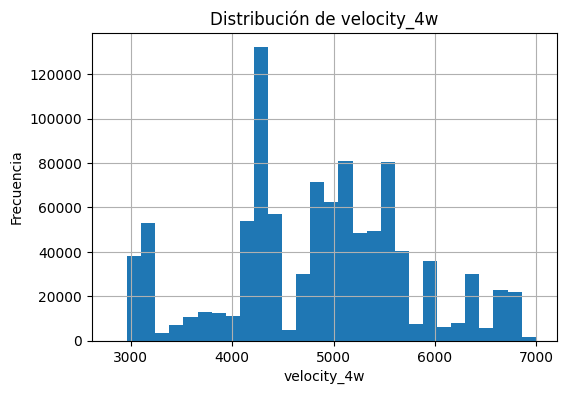

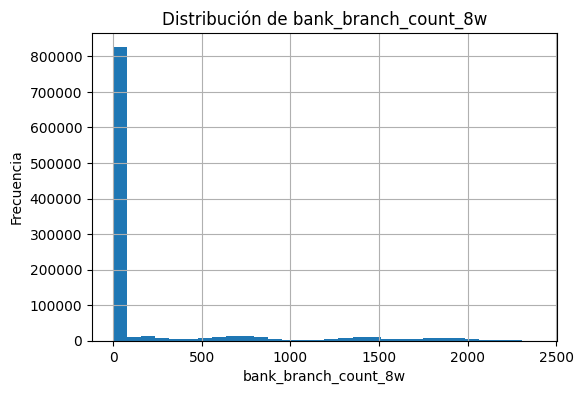

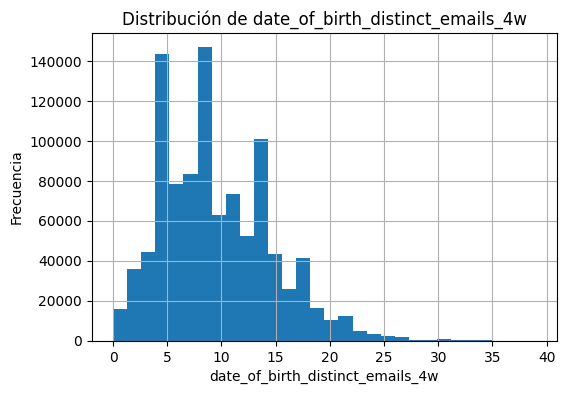

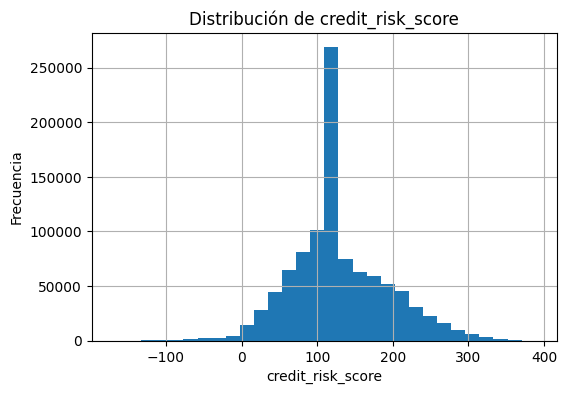

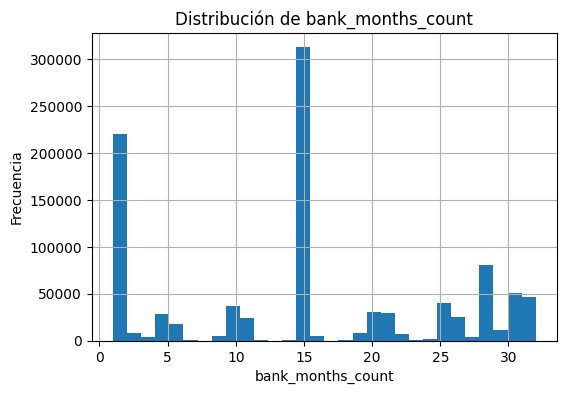

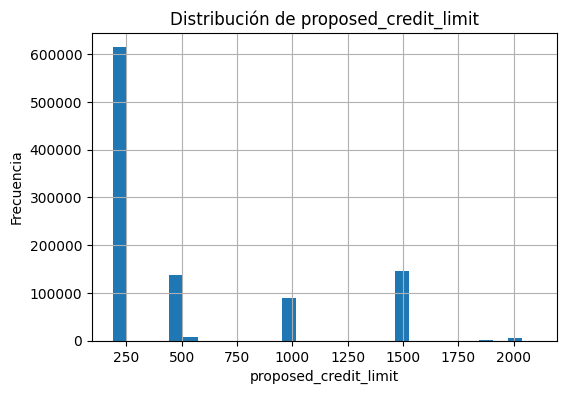

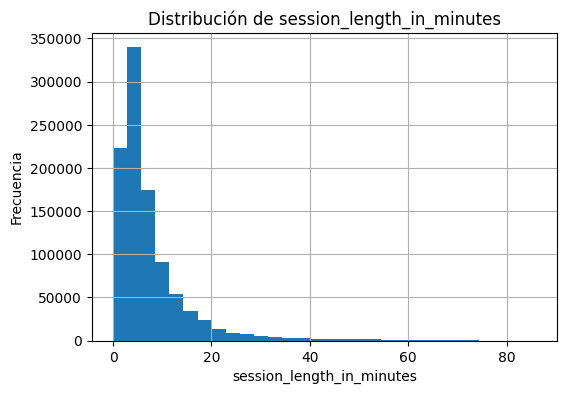

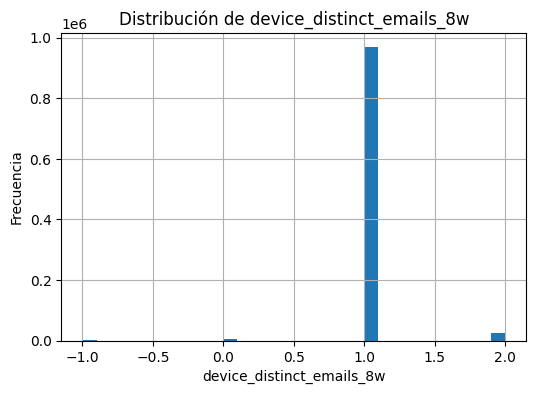

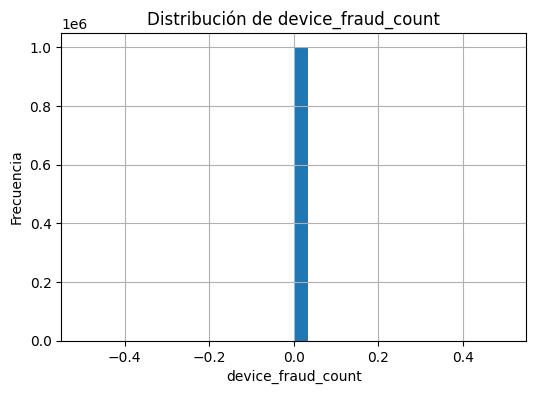

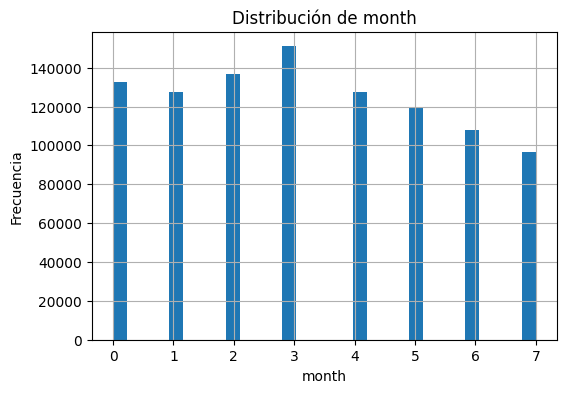

In [12]:
#para realizar los histogramas
for col in numerical_columns:
    plt.figure(figsize=(6,4))
    df[col].hist(bins=30)
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.show()

A partir de los histogramas, se observa que la mayoría de las variables presentan distribuciones claramente asimétricas positivas, con una fuerte concentración de valores bajos y colas largas hacia la derecha. Esto es especialmente evidente en variables como days_since_request, current_address_months_count, session_length_in_minutes o bank_branch_count_8w, donde la mayor parte de los datos se agrupa en valores cercanos a cero.

En variables como intended_balcon_amount y proposed_credit_limit se observa una gran concentración en valores concretos, lo que indica la posible existencia de valores discretizados o agrupaciones específicas dentro del dataset.

Variables como customer_age muestran una distribución discreta con mayor concentración en edades medias (entre 20 y 50 años), mientras que month presenta una distribución relativamente uniforme, lo que indica que los datos están equilibrados a lo largo del tiempo. Finalmente, variables como device_distinct_emails_8w y device_fraud_count presentan una alta concentración en un único valor.

En conjunto, el análisis muestra que muchas variables no siguen una distribución normal y presentan valores extremos, lo que sugiere la necesidad de analizar outliers y considerar posibles transformaciones en fases posteriores.

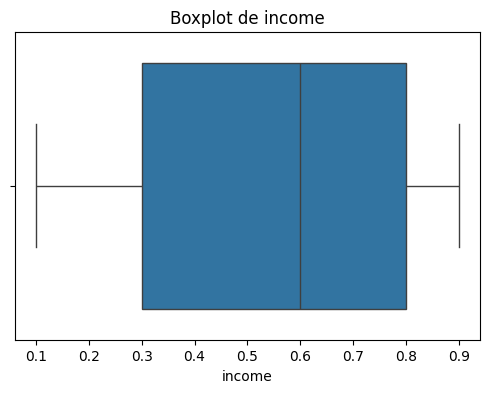

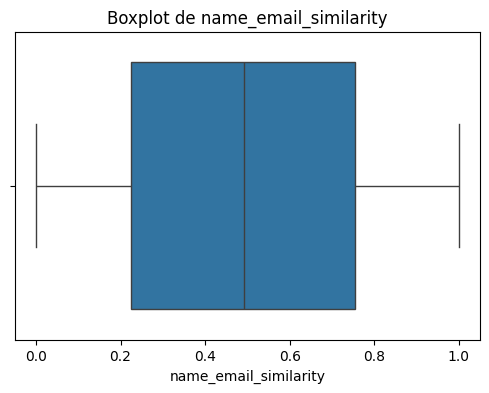

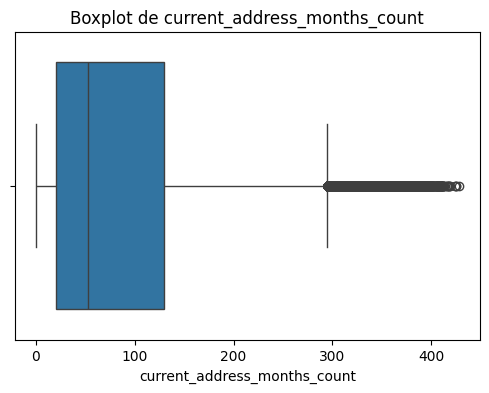

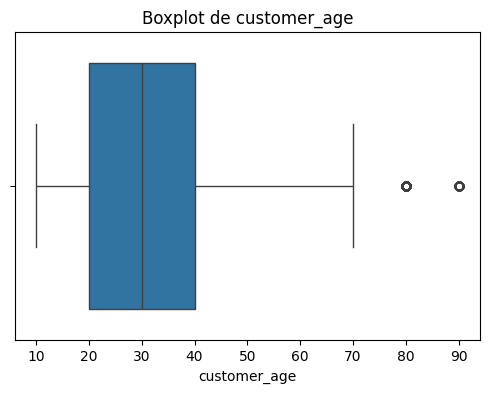

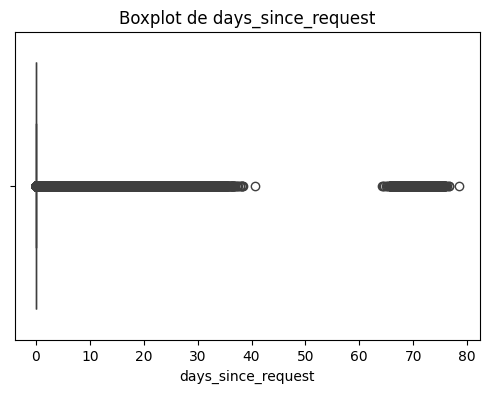

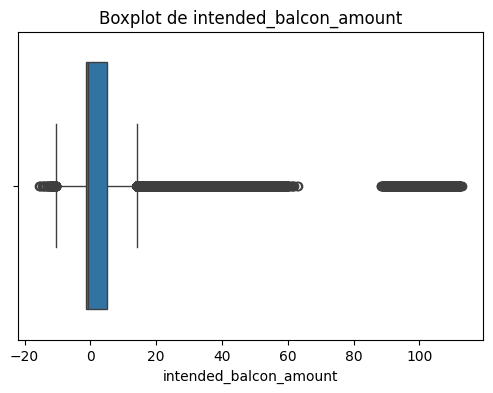

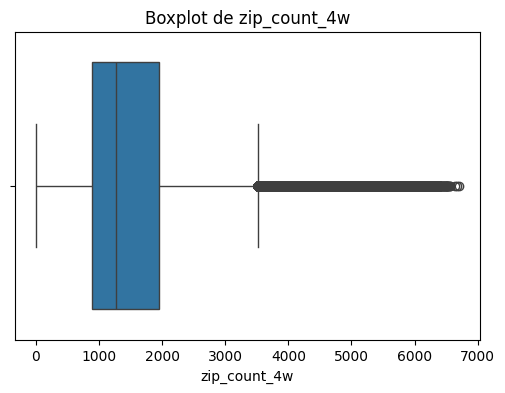

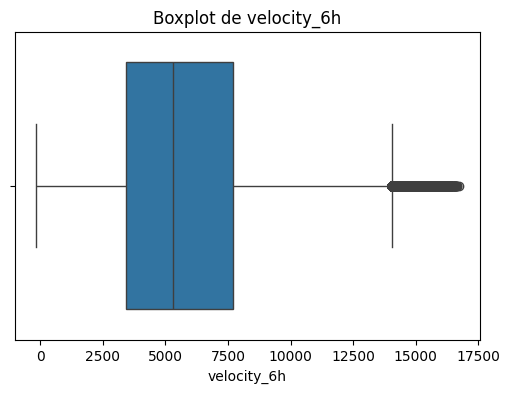

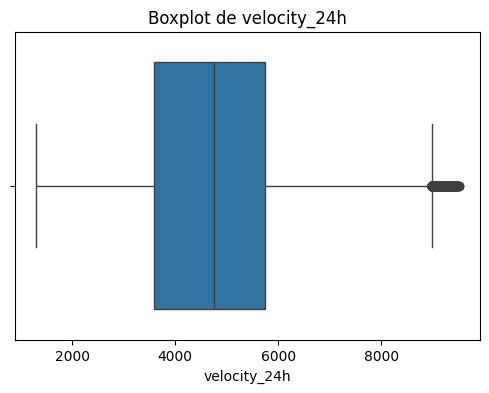

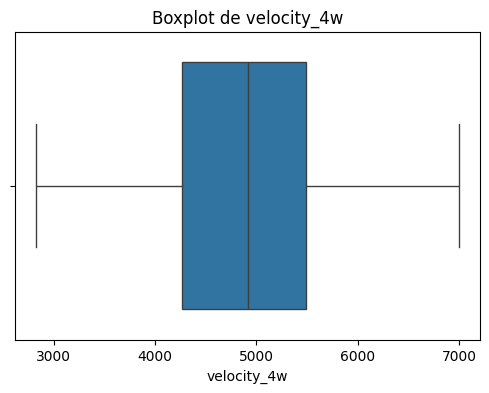

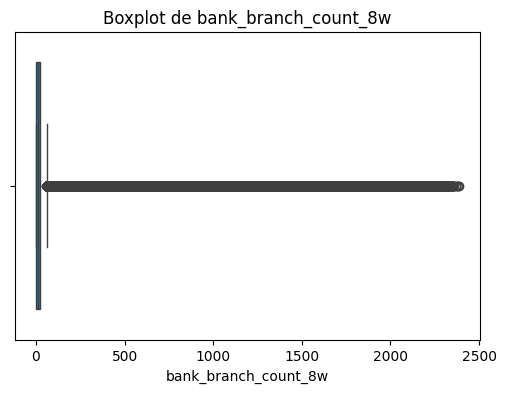

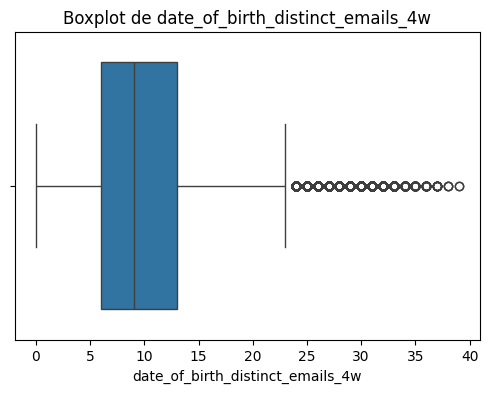

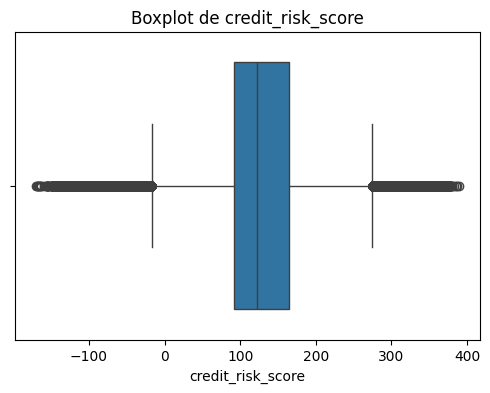

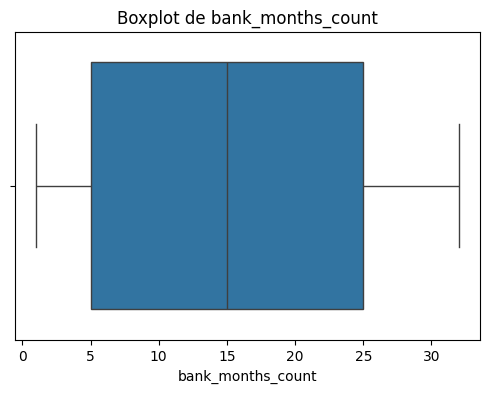

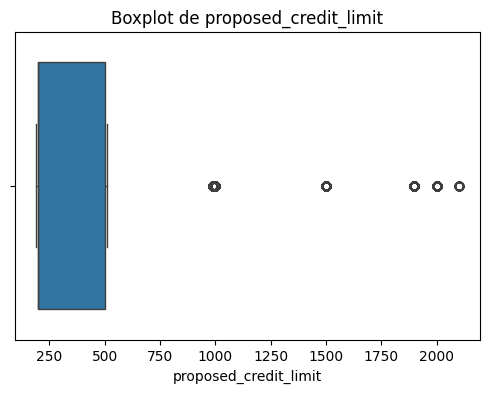

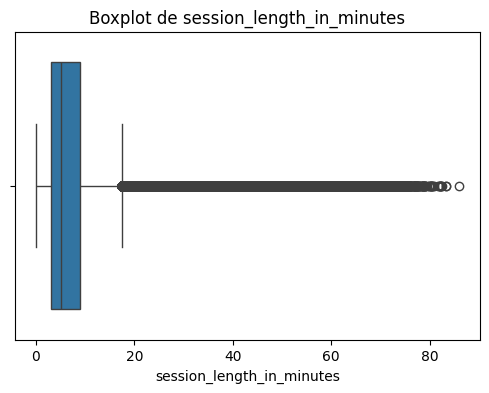

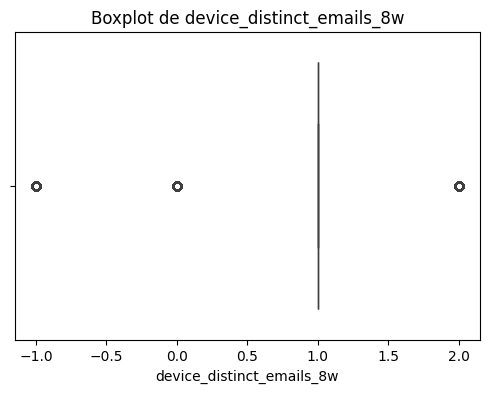

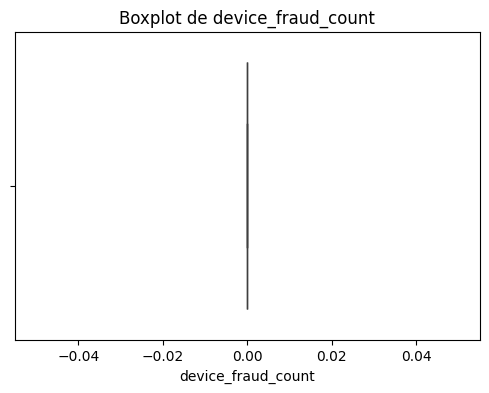

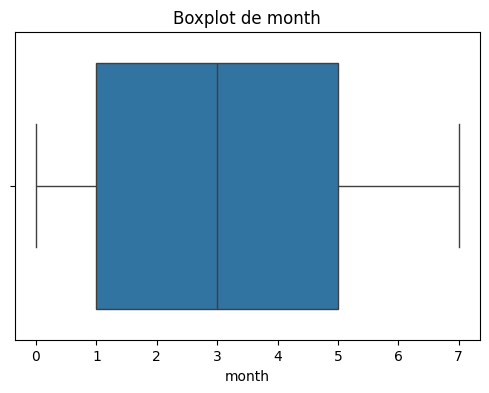

In [13]:
#para realizar los boxplots
for col in numerical_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot de {col}")
    plt.show()

A partir de los boxplots, se observa la presencia de numerosos valores atípicos en gran parte de las variables numéricas especialmente en aquellas relacionadas con actividad e importes, como intended_balcon_amount, proposed_credit_limit, velocity_6h, velocity_24h y zip_count_4w.Estas variables presentan colas largas y una elevada dispersión, lo que confirma la asimetría observada previamente en los histogramas.

En variables como days_since_request, session_length_in_minutes o bank_branch_count_8w, la mayoría de los valores se concentran en rangos bajos, apareciendo múltiples outliers en valores altos.

Aunque se han identificado numerosos valores atípicos, no se eliminan en esta fase, ya que en problemas de detección de fraude estos valores extremos pueden ser especialmente relevantes para identificar comportamientos anómalos.

### Variables categóricas

In [14]:
#Variables Categóricas (incluyendo binarias + object)
categorical_columns = list(df.select_dtypes(include='object').columns) + binary_columns
categorical_columns

C:\Users\carte\AppData\Local\Temp\ipykernel_7164\3528323239.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = list(df.select_dtypes(include='object').columns) + binary_columns


['payment_type',
 'employment_status',
 'housing_status',
 'source',
 'device_os',
 'fraud_bool',
 'email_is_free',
 'phone_home_valid',
 'phone_mobile_valid',
 'has_other_cards',
 'foreign_request',
 'keep_alive_session']

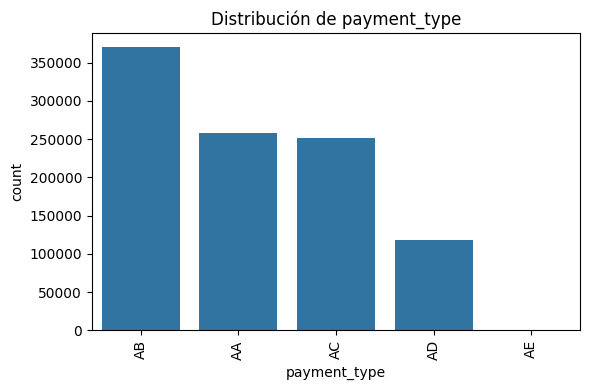

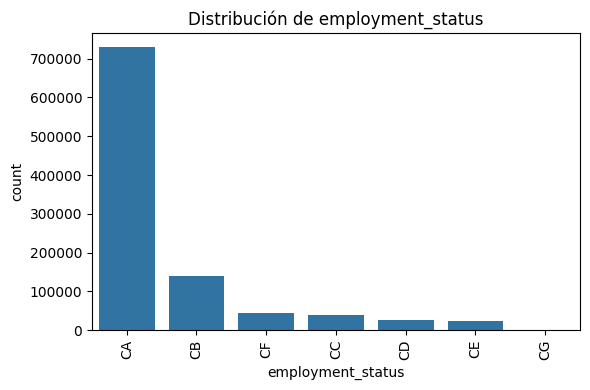

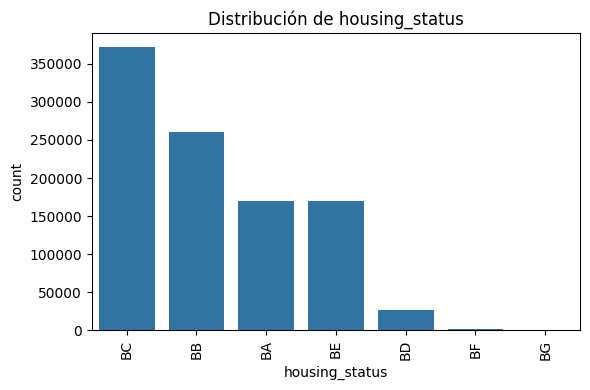

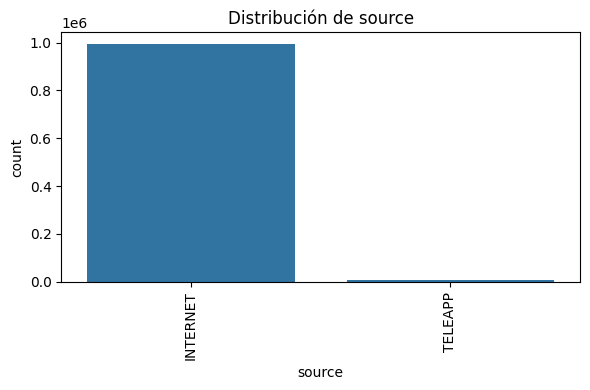

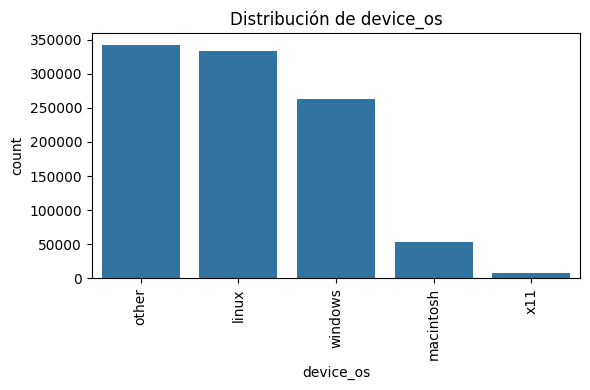

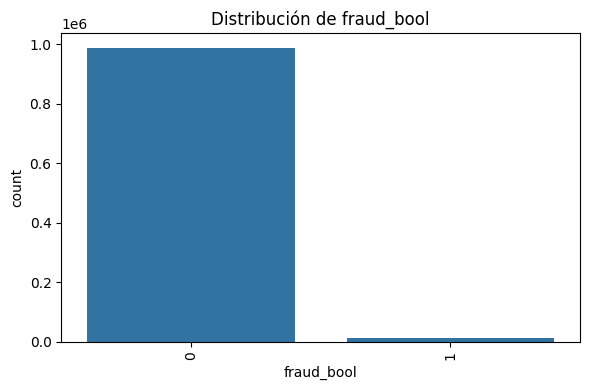

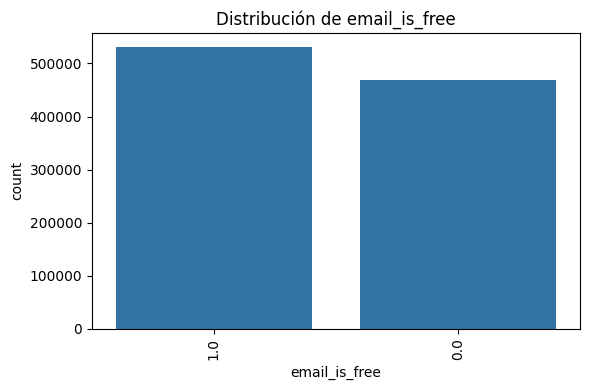

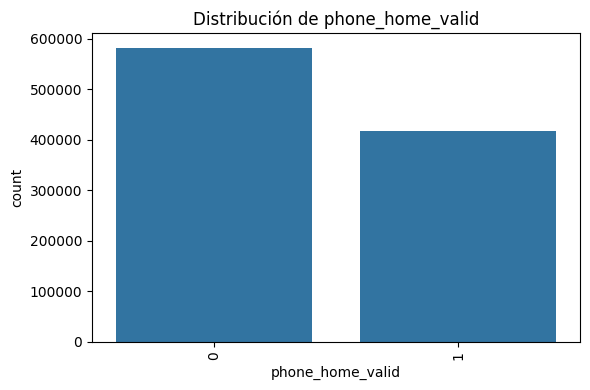

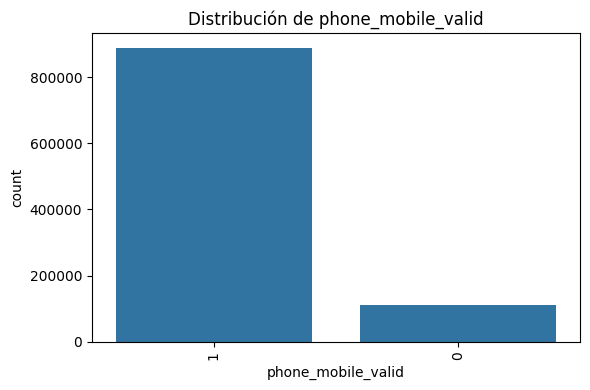

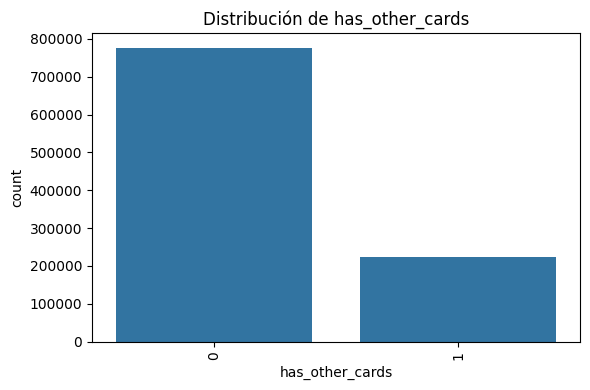

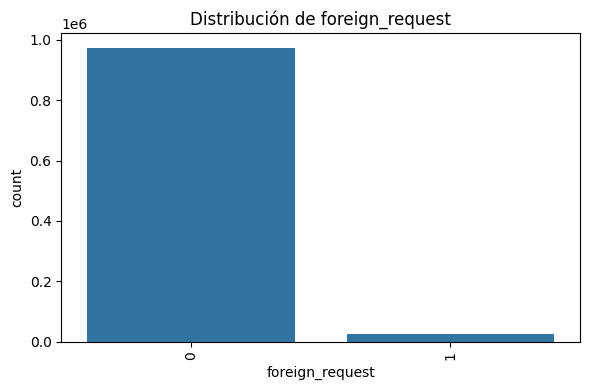

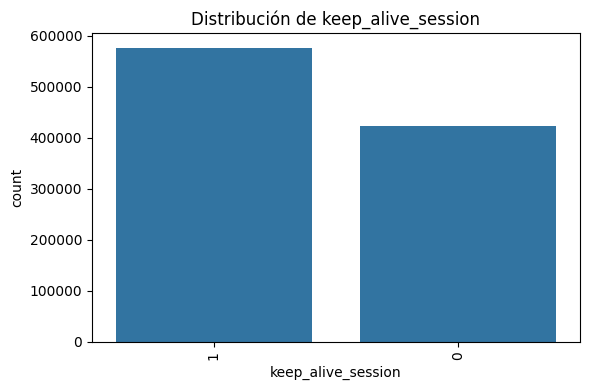

In [15]:
#hacemos los barplots
for col in categorical_columns:
    plt.figure(figsize=(6,4))
    sns.countplot(x=df[col], order=df[col].value_counts().index)
    plt.title(f"Distribución de {col}")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

A partir de los gráficos de barras, se observa que las variables categóricas presentan en general una distribución desigual entre sus categorías, con predominio claro de algunas clases frente a otras. La variable objetivo presenta un fuerte desbalanceo de clases, con una proporción muy reducida de casos de fraude. Este desbalanceo es esperable en datasets de gran tamaño y en problemas de fraude, donde determinadas categorías dominan claramente el comportamiento de los datos.

No se han realizado agrupaciones de categorías en esta fase, ya que, a pesar del desbalanceo observado, las categorías minoritarias no presentan un impacto significativo debido al gran volumen de datos disponible.

## ANÁLISIS MULTIVARIANTE

### Numérica vs Numérica

In [16]:
corr_numerical = df[numerical_columns].corr()
corr_numerical.round(3)

,income,name_email_similarity,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,credit_risk_score,bank_months_count,proposed_credit_limit,session_length_in_minutes,device_distinct_emails_8w,device_fraud_count,month
income,1.000,-0.039,-0.037,0.126,-0.016,0.059,-0.081,-0.096,-0.101,-0.106,0.007,-0.062,0.157,-0.036,0.109,-0.056,-0.010,NaN,0.116
name_email_similarity,-0.039,1.000,0.050,-0.049,-0.008,0.029,0.025,0.025,0.035,0.040,-0.001,0.023,0.045,-0.000,0.073,0.006,-0.018,NaN,-0.043
current_address_months_count,-0.037,0.050,1.000,0.142,-0.057,0.057,0.047,0.027,0.019,0.026,0.054,-0.174,0.087,0.050,0.130,-0.033,-0.001,NaN,-0.024
customer_age,0.126,-0.049,0.142,1.000,-0.036,-0.013,-0.014,-0.022,-0.010,-0.004,0.048,-0.420,0.152,0.003,0.149,0.026,0.026,NaN,0.006
days_since_request,-0.016,-0.008,-0.057,-0.036,1.000,0.020,0.000,0.028,0.024,0.018,-0.018,0.019,-0.081,0.030,-0.069,0.050,0.009,NaN,-0.018
intended_balcon_amount,0.059,0.029,0.057,-0.013,0.020,1.000,0.002,0.043,0.064,0.051,0.103,-0.027,0.002,0.036,0.058,0.022,-0.020,NaN,-0.043
zip_count_4w,-0.081,0.025,0.047,-0.014,0.000,0.002,1.000,0.142,0.201,0.303,0.006,0.127,-0.094,0.046,-0.012,0.040,0.021,NaN,-0.287
velocity_6h,-0.096,0.025,0.027,-0.022,0.028,0.043,0.142,1.000,0.464,0.400,0.020,0.119,-0.132,-0.002,-0.025,0.054,0.030,NaN,-0.409
velocity_24h,-0.101,0.035,0.019,-0.010,0.024,0.064,0.201,0.464,1.000,0.539,0.036,0.155,-0.135,-0.005,0.018,0.067,0.035,NaN,-0.550
velocity_4w,-0.106,0.040,0.026,-0.004,0.018,0.051,0.303,0.400,0.539,1.000,0.031,0.242,-0.154,0.006,0.052,0.079,0.042,NaN,-0.848


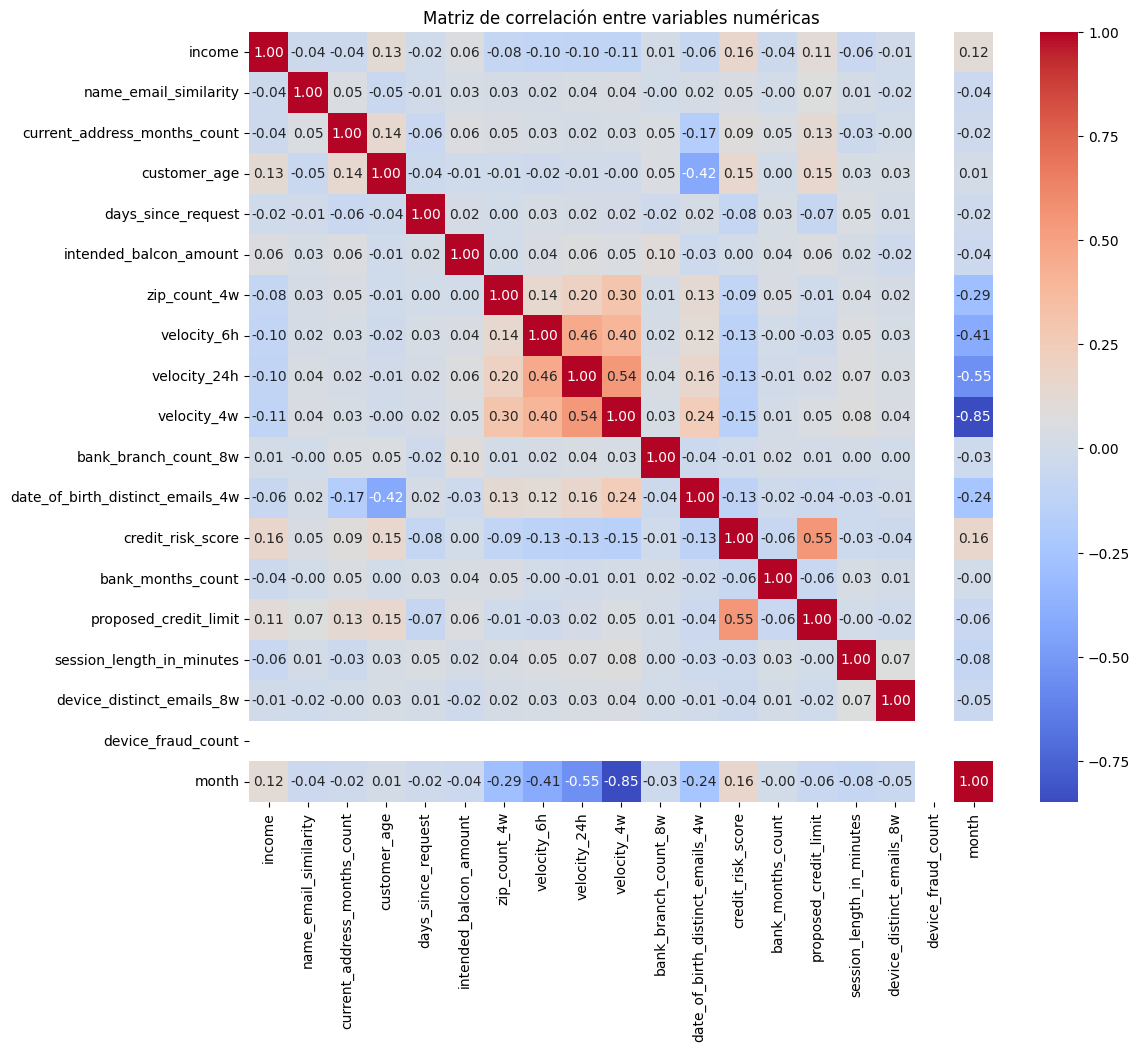

In [17]:
plt.figure(figsize=(12,10))
sns.heatmap(corr_numerical,
            annot=True,
            cmap="coolwarm",
            fmt=".2f")

plt.title("Matriz de correlación entre variables numéricas")
plt.show()

La matriz de correlación muestra que la mayoría de las variables presentan baja correlación entre sí. Sin embargo, se observa una alta correlación entre variables relacionadas con la velocidad de transacciones (velocity_6h, velocity_24h, velocity_4w), lo que sugiere redundancia entre ellas.

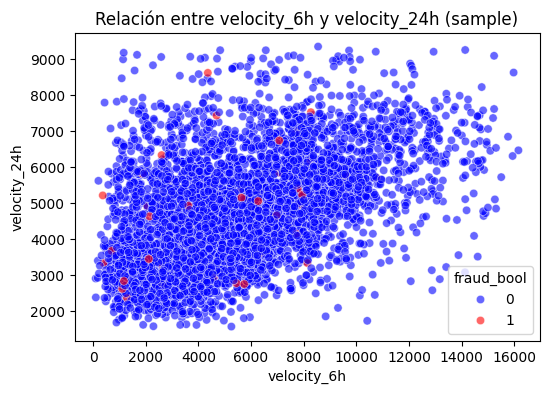

In [18]:
#scatter plot de las variables con más correlación
#scatter de las velocidades

df_sample = df.sample(5000, random_state=42)

plt.figure(figsize=(6,4))
sns.scatterplot(
    data=df_sample,
    x='velocity_6h',
    y='velocity_24h',
    hue='fraud_bool',
    palette={0: 'blue', 1: 'red'},
    alpha=0.6
)
plt.title('Relación entre velocity_6h y velocity_24h (sample)')
plt.show()

C:\Users\carte\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


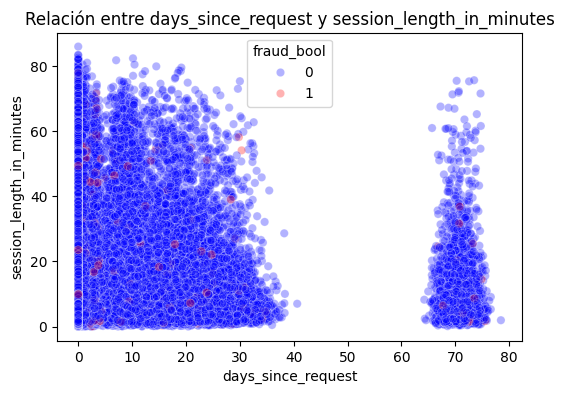

In [21]:
#scatter actividad vs tiempo
plt.figure(figsize=(6,4))
sns.scatterplot(
    x=df['days_since_request'],
    y=df['session_length_in_minutes'],
    hue=df['fraud_bool'],
    palette={0: 'blue', 1: 'red'},
    alpha=0.3
)
plt.title('Relación entre days_since_request y session_length_in_minutes')
plt.show()

Los gráficos de dispersión refuerzan la idea de que, aunque existen algunas relaciones entre variables, no se observa una separación clara entre las clases, lo que confirma la necesidad de utilizar modelos de machine learning para capturar patrones más complejos.

### Numérica vs Categórica

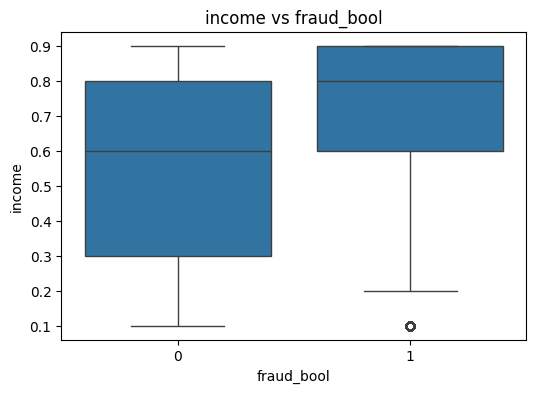

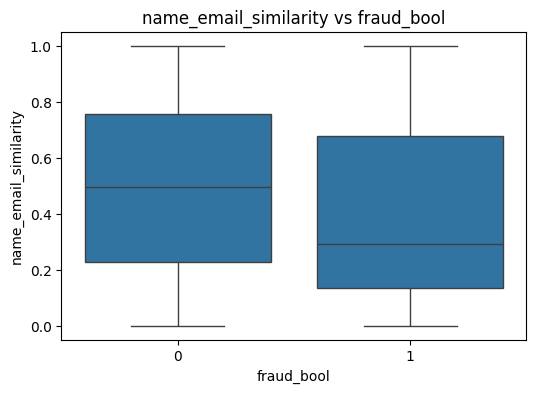

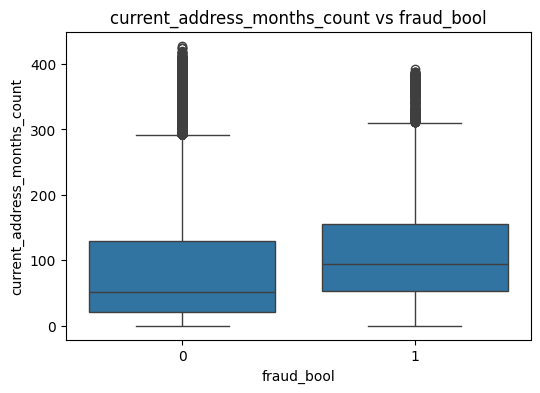

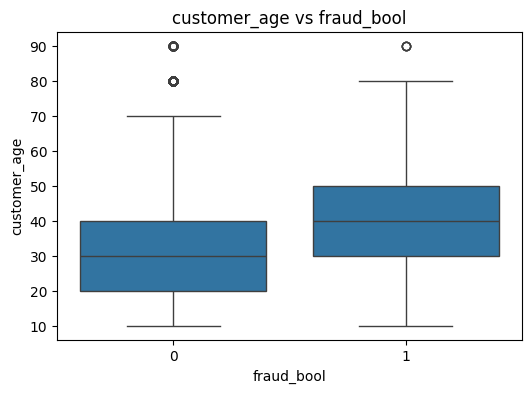

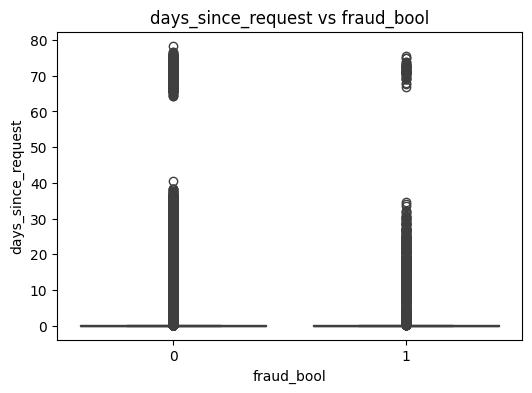

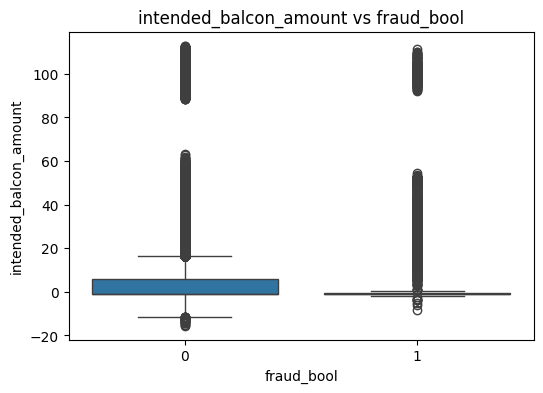

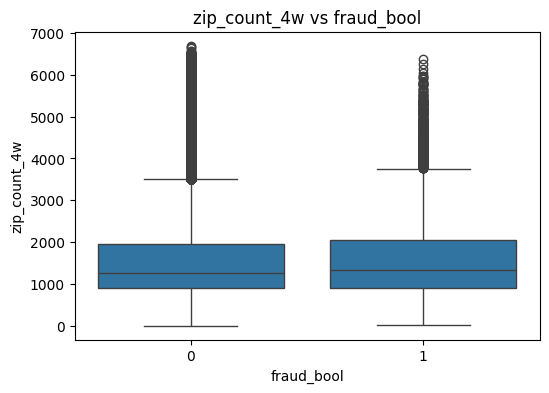

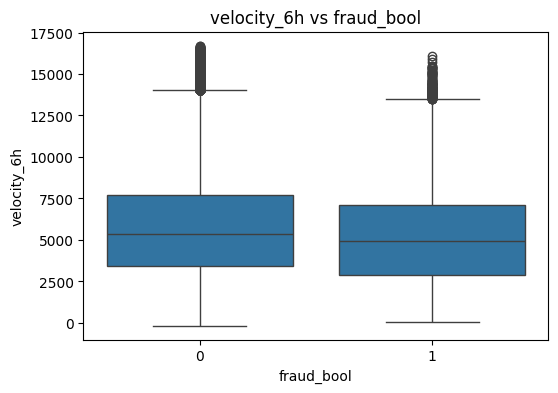

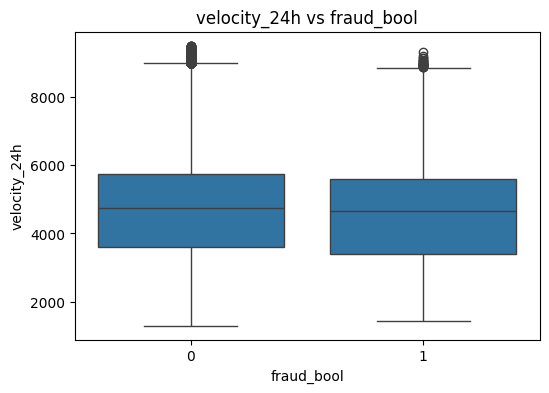

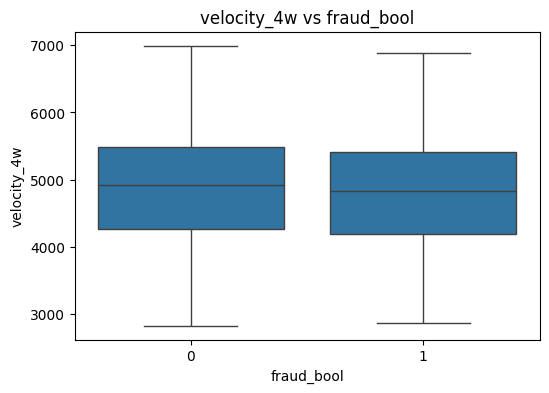

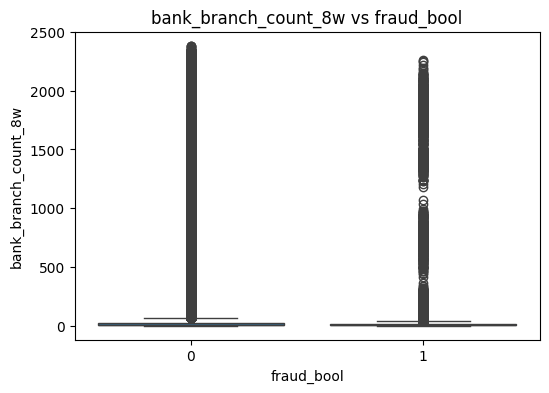

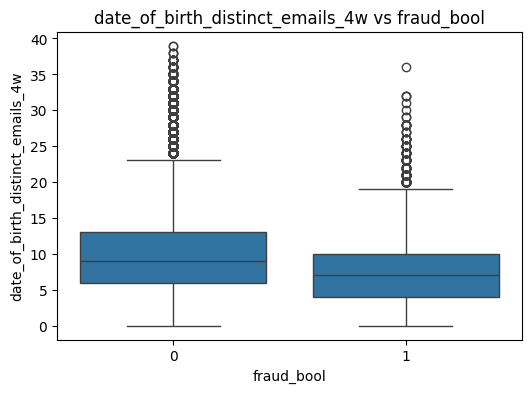

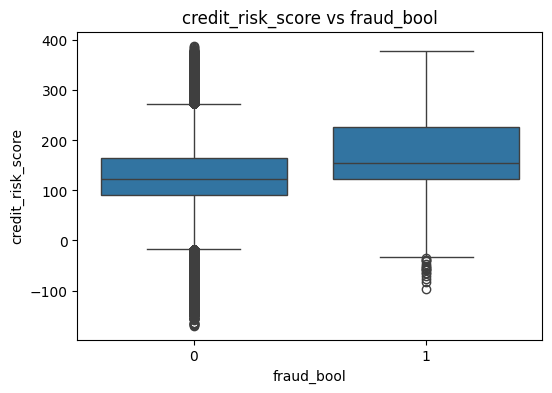

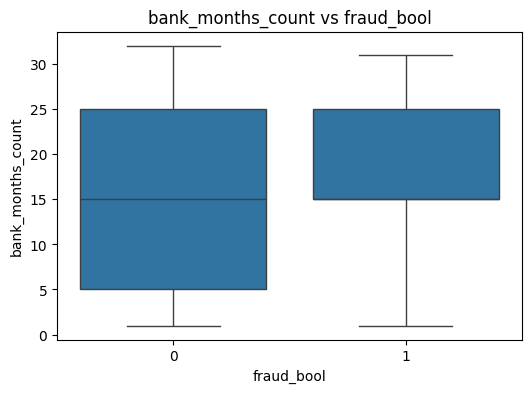

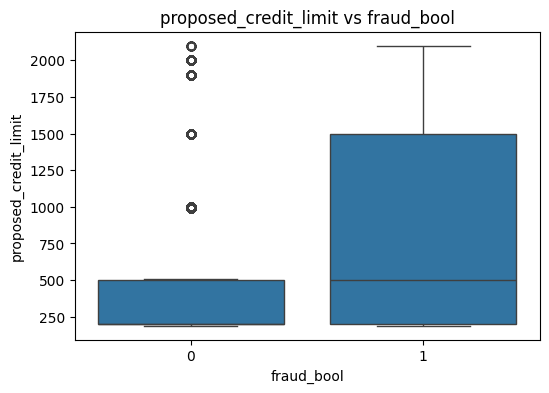

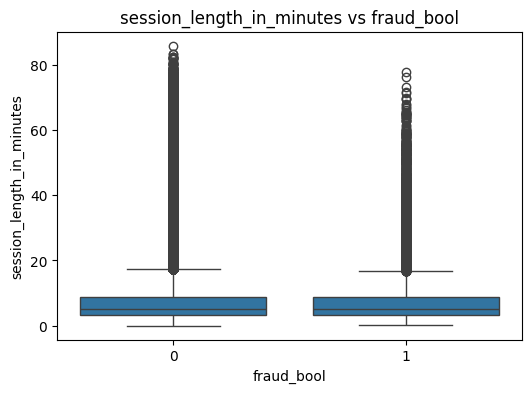

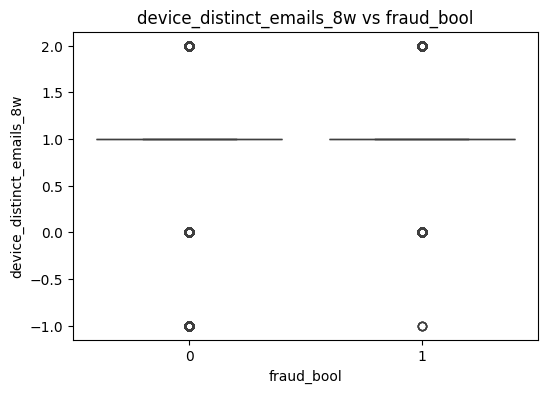

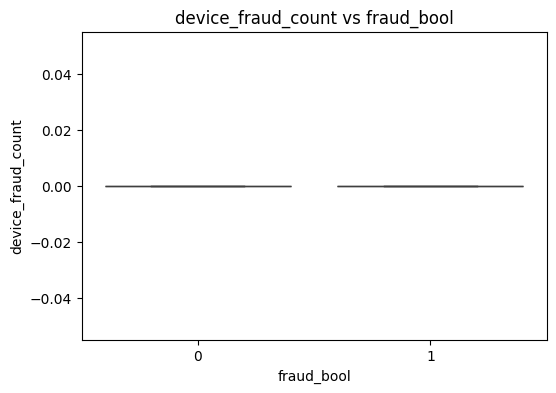

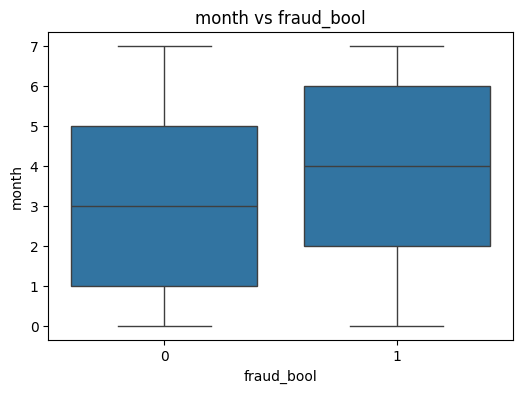

In [22]:
#hacemos los boxplots en relacion a la variable objetivo
for col in numerical_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df["fraud_bool"], y=df[col])
    plt.title(f"{col} vs fraud_bool")
    plt.xlabel("fraud_bool")
    plt.ylabel(col)
    plt.show()

El análisis de las variables numéricas respecto a la variable objetivo muestra que algunas variables presentan diferencias en su distribución entre casos de fraude y no fraude, especialmente en aquellas relacionadas con la actividad del usuario.

### Categórica vs Categórica

In [23]:
# hacemos la tabla de contingencia para cada variable
for col in categorical_columns:
    print(f"\n{col}")
    print(pd.crosstab(df[col], df['fraud_bool'], normalize='index'))


payment_type
fraud_bool           0         1
payment_type                    
AA            0.994718  0.005282
AB            0.988749  0.011251
AC            0.983302  0.016698
AD            0.989178  0.010822
AE            0.996540  0.003460

employment_status
fraud_bool                0         1
employment_status                    
CA                 0.987814  0.012186
CB                 0.993109  0.006891
CC                 0.975316  0.024684
CD                 0.996230  0.003770
CE                 0.997664  0.002336
CF                 0.998070  0.001930
CG                 0.984547  0.015453

housing_status
fraud_bool             0         1
housing_status                    
BA              0.962534  0.037466
BB              0.993992  0.006008
BC              0.993852  0.006148
BD              0.991361  0.008639
BE              0.996559  0.003441
BF              0.995806  0.004194
BG              0.996032  0.003968

source
fraud_bool         0         1
source                  

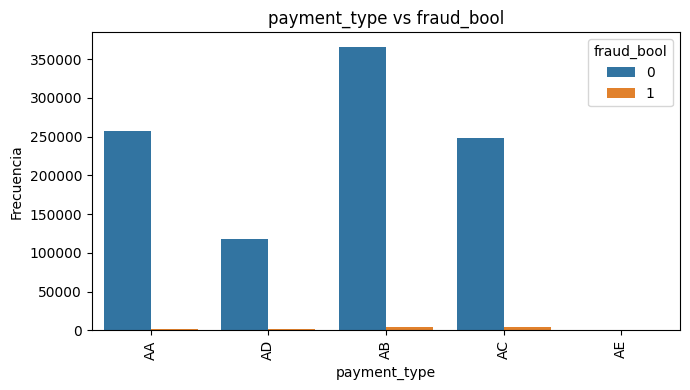

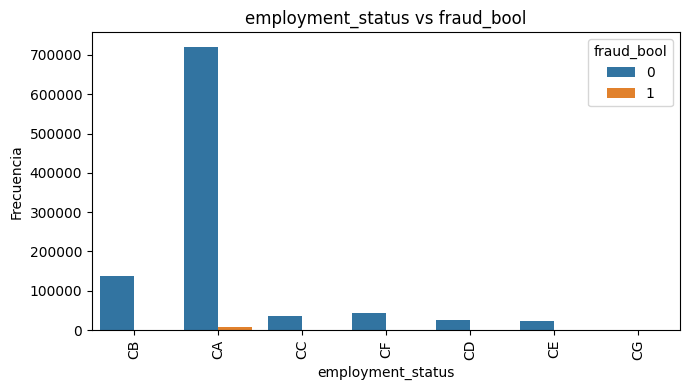

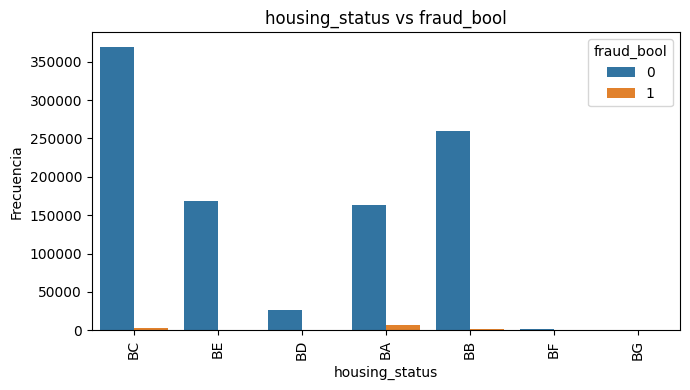

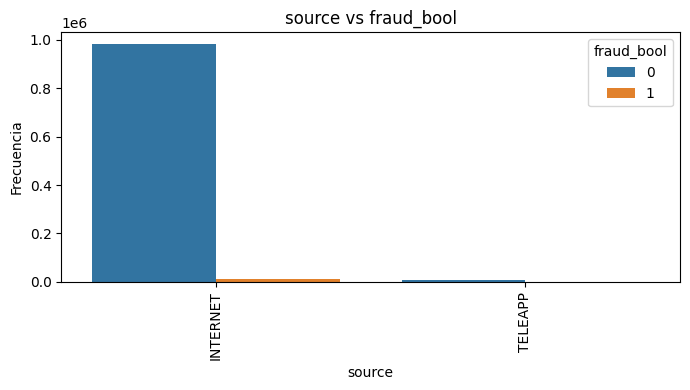

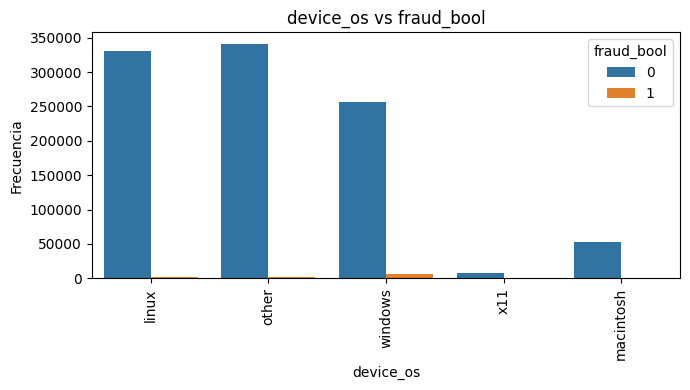

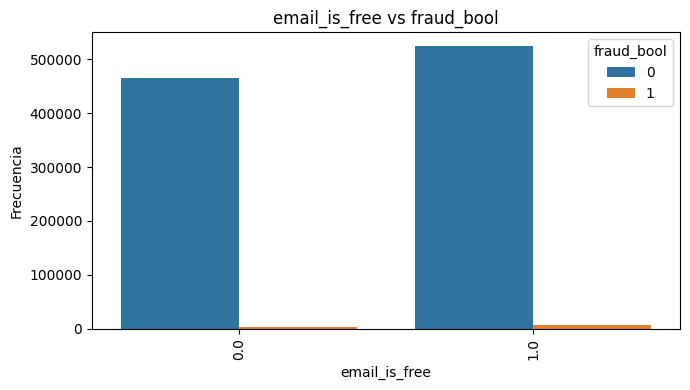

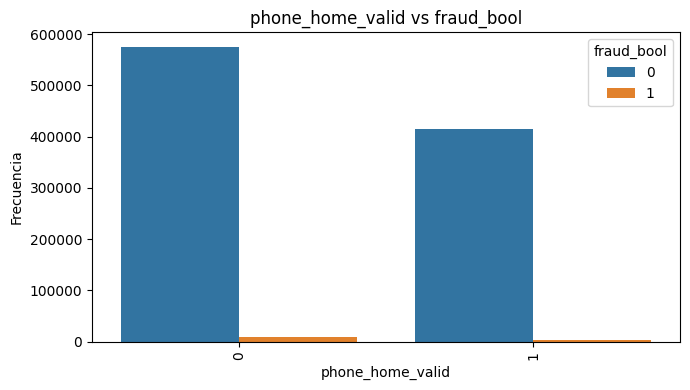

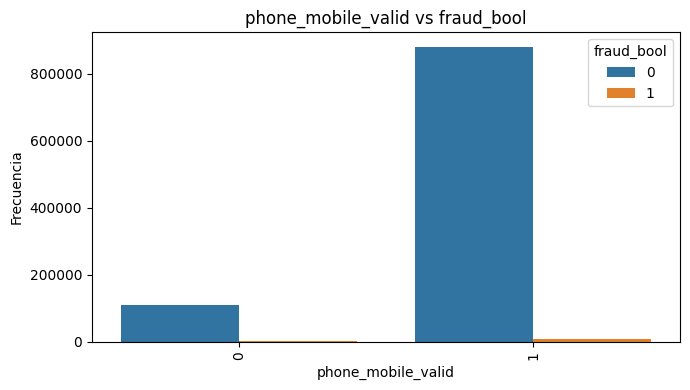

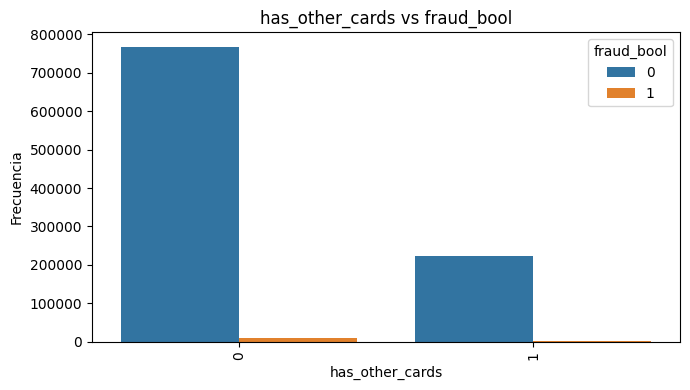

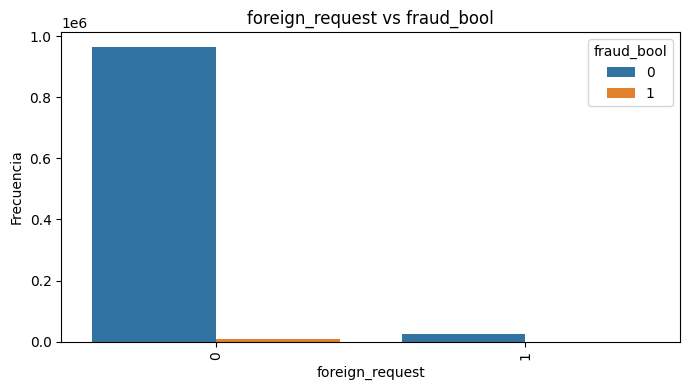

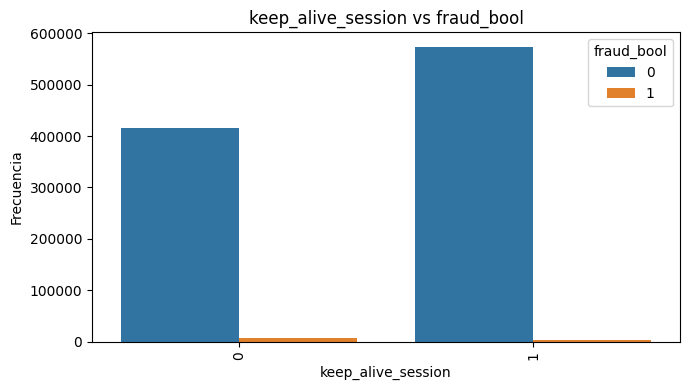

In [25]:
#lo representamos en gráficos
for col in categorical_columns:
    
    if col != "fraud_bool":
        
        plt.figure(figsize=(7,4))
        sns.countplot(data=df, x=col, hue="fraud_bool")
        
        plt.title(f"{col} vs fraud_bool")
        plt.xlabel(col)
        plt.ylabel("Frecuencia")
        plt.xticks(rotation=90)
        plt.tight_layout()
        plt.show()

El análisis de las variables categóricas muestra que existen diferencias en la proporción de fraude entre categorías, aunque en general estas diferencias no son muy pronunciadas. Destacan variables como housing_status, donde la categoría BA presenta una mayor proporción de fraude, y employment_status, donde categorías como CC muestran valores más elevados.

Asimismo, en variables como device_os y foreign_request se observan diferencias relevantes, siendo “windows” y las solicitudes extranjeras las que presentan mayores tasas de fraude.

En las variables binarias, se aprecia que ciertas categorías como no tener teléfono válido o no mantener la sesión activa están asociadas a un mayor porcentaje de fraude.

En conjunto, aunque algunas variables muestran cierta capacidad explicativa, ninguna permite por sí sola discriminar claramente el fraude, siendo necesario combinarlas en modelos más complejos.

In [32]:
#hacemos chi2 y el p-value y hacemos una tabla
from scipy.stats import chi2_contingency
import pandas as pd

resultados_chi2 = []

for col in categorical_columns:
    
    if col != "fraud_bool":
        # tabla de contingencia
        tabla = pd.crosstab(df[col], df["fraud_bool"])
        #test chi2
        chi2, p, dof, expected = chi2_contingency(tabla)

        #decision sobre p-value
        decision = "Se podría descartar" if p > 0.05 else "Relacionada con la variable objetivo"
        
        resultados_chi2.append({
            "variable": col,
            "chi2": chi2,
            "p_value": p,
            "decision": decision
        })
#convertir a dataframe
resultados_chi2 = pd.DataFrame(resultados_chi2)

# redondear a 4 decimales
resultados_chi2["chi2"] = resultados_chi2["chi2"].round(4)
resultados_chi2["p_value"] = resultados_chi2["p_value"].round(4)

# ordenar por p_value
resultados_chi2 = resultados_chi2.sort_values("p_value")
resultados_chi2

,variable,chi2,p_value,decision
0,payment_type,1528.3420,0.0000,Relacionada con la variable objetivo
1,employment_status,1572.4990,0.0000,Relacionada con la variable objetivo
2,housing_status,13202.7877,0.0000,Relacionada con la variable objetivo
4,device_os,6478.9459,0.0000,Relacionada con la variable objetivo
6,phone_home_valid,1233.2813,0.0000,Relacionada con la variable objetivo
5,email_is_free,770.9518,0.0000,Relacionada con la variable objetivo
7,phone_mobile_valid,173.3014,0.0000,Relacionada con la variable objetivo
8,has_other_cards,1235.1617,0.0000,Relacionada con la variable objetivo
10,keep_alive_session,2528.7544,0.0000,Relacionada con la variable objetivo
9,foreign_request,284.0608,0.0000,Relacionada con la variable objetivo


Los resultados muestran que la mayoría de variables presentan un p-value inferior a 0.05, lo que indica que existe una relación estadísticamente significativa con la variable de fraude. Esto sugiere que estas variables pueden aportar información relevante para la predicción del fraude.

In [33]:
df.nunique().sort_values()

device_fraud_count                       1
fraud_bool                               2
keep_alive_session                       2
source                                   2
phone_home_valid                         2
phone_mobile_valid                       2
email_is_free                            2
foreign_request                          2
has_other_cards                          2
device_distinct_emails_8w                4
device_os                                5
payment_type                             5
employment_status                        7
housing_status                           7
month                                    8
customer_age                             9
income                                   9
proposed_credit_limit                   12
bank_months_count                       32
date_of_birth_distinct_emails_4w        40
current_address_months_count           422
credit_risk_score                      547
bank_branch_count_8w                  2326
zip_count_4

Se han eliminado variables con baja variabilidad, como device_fraud_count y device_distinct_emails_8w, así como variables con escasa capacidad explicativa, como month y zip_count_4w.

Asimismo, se ha eliminado la variable velocity_6h debido a su alta correlación con otras variables de velocidad, con el objetivo de reducir la redundancia en el modelo.

El resto de variables se han mantenido al aportar información relevante para la predicción del fraude.

In [34]:
#guardamos el df limpio en un csv
df_final = df.drop(columns=[
    'device_fraud_count',
    'device_distinct_emails_8w',
    'month',
    'velocity_6h',
    'zip_count_4w'
])

df_final.to_csv("df_final.csv", index=False)

In [35]:
df_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 26 columns):
 #   Column                            Non-Null Count    Dtype  
---  ------                            --------------    -----  
 0   fraud_bool                        1000000 non-null  int64  
 1   income                            1000000 non-null  float64
 2   name_email_similarity             1000000 non-null  float64
 3   current_address_months_count      1000000 non-null  float64
 4   customer_age                      1000000 non-null  int64  
 5   days_since_request                1000000 non-null  float64
 6   intended_balcon_amount            1000000 non-null  float64
 7   payment_type                      1000000 non-null  str    
 8   velocity_24h                      1000000 non-null  float64
 9   velocity_4w                       1000000 non-null  float64
 10  bank_branch_count_8w              1000000 non-null  int64  
 11  date_of_birth_distinct_emails_4w  1000000 non-nul

## PCA

In [54]:
import pandas as pd

df_final = pd.read_csv("df_final.csv")
df_final.head(5)

,fraud_bool,income,name_email_similarity,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,velocity_24h,velocity_4w,...,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session
0,0,0.3,0.986506,25.0,40,0.006735,102.453711,AA,7850.955007,6742.080561,...,0,1,9.0,0,1500.0,0,INTERNET,16.224843,linux,1
1,0,0.8,0.617426,89.0,20,0.010095,-0.849551,AD,5745.251481,5941.664859,...,1,1,2.0,0,1500.0,0,INTERNET,3.363854,other,1
2,0,0.8,0.996707,14.0,40,0.012316,-1.490386,AB,5471.988958,5992.555113,...,0,1,30.0,0,200.0,0,INTERNET,22.730559,windows,0
3,0,0.6,0.475100,14.0,30,0.006991,-1.863101,AB,6755.344479,5970.336831,...,0,1,1.0,0,200.0,0,INTERNET,15.215816,linux,1
4,0,0.9,0.842307,29.0,40,5.742626,47.152498,AA,5124.046930,5940.734212,...,1,1,26.0,0,200.0,0,INTERNET,3.743048,other,0


In [55]:
#decidimos no hacer get.dummies y quedarnos con las variables numericas
numerical_columns_pca = df_final.select_dtypes(include=['int64', 'float64']).columns
df_pca = df_final[numerical_columns_pca]

In [56]:
#eliminamos la variable objetivo
df_pca = df_pca.drop(columns=['fraud_bool'])

In [57]:
#estandarizamos los datos
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_pca)

In [58]:
#Aplicamos PCA completo para ver la varianza explicada
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

pca = PCA()
pca.fit(df_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

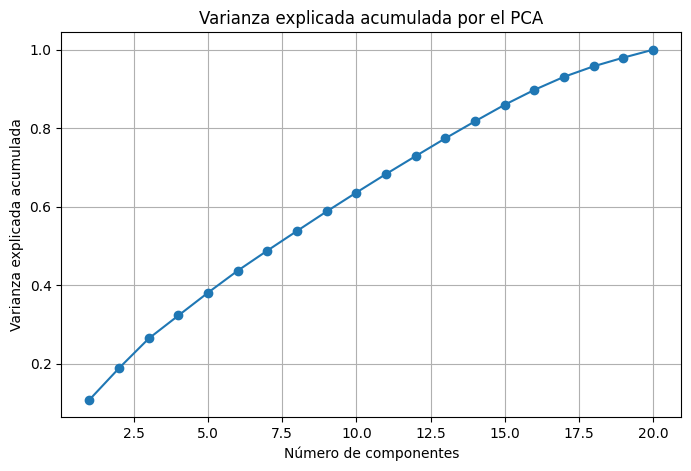

In [51]:
#graficamos
plt.figure(figsize=(8,5))
plt.plot(range(1, len(cumulative_variance)+1), cumulative_variance, marker='o')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.title('Varianza explicada acumulada por el PCA')
plt.grid(True)
plt.show()

In [59]:
#elegimos el numero optimo de componentes que explique el 90%de la varianza
n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1
print("Número de componentes para explicar al menos el 90% de la varianza:", n_components_90)

Número de componentes para explicar al menos el 90% de la varianza: 17


In [63]:
from sklearn.decomposition import PCA
import pandas as pd

# PCA final con el número óptimo de componentes
pca_final = PCA(n_components=n_components_90)
pca_result = pca_final.fit_transform(df_scaled)

# Creamos el dataframe con componentes principales
columns_pca = [f'PC{i+1}' for i in range(n_components_90)]
df_pca_final = pd.DataFrame(pca_result, columns=columns_pca)

df_pca_final.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17
0,-0.536041,3.818312,1.800515,1.024429,0.868860,1.450179,1.866525,0.255098,0.041021,-0.586809,0.995702,1.596910,-1.735348,2.197154,-1.179545,-2.279395,0.085760
1,-0.598963,1.242984,1.956784,-1.495183,-0.951212,-1.319376,0.710136,0.192383,0.116900,0.536366,0.976825,0.058277,0.065791,0.098592,-0.854890,1.266939,1.145934
2,-1.458806,0.743630,-0.023897,-0.079944,1.631787,1.368026,-0.892506,0.024935,-0.257476,0.378197,0.660443,-0.327270,-2.246646,-1.650086,0.036740,0.244724,-0.187154
3,-2.293671,0.637734,0.455097,-1.178648,0.724128,-0.690679,0.682616,0.089110,-0.831225,-0.974044,0.244322,0.299942,-0.620518,0.072517,-0.083620,0.466657,-0.437689
4,-0.015639,0.815480,-0.860796,1.761442,0.107055,0.572512,-0.039402,1.857692,0.136517,0.559131,-0.406919,-0.091452,-1.542397,-0.523559,-0.946740,-0.902366,1.625074


In [64]:
#guardamos el nuevo csv
df_pca_final.to_csv("df_pca_final.csv", index=False)

Antes de aplicar el PCA, se ha partido del DataFrame final previamente depurado, incluyendo el tratamiento de nulos, la eliminación de duplicados y la selección de variables más relevantes. Posteriormente, se han estandarizado las variables numéricas, ya que el PCA es sensible a la escala de los datos.

A continuación, se ha calculado la varianza explicada acumulada para determinar el número óptimo de componentes principales. Se ha seleccionado el número de componentes necesario para explicar al menos el 90% de la varianza total, logrando así una reducción de dimensionalidad sin perder una cantidad significativa de información.

Finalmente, se ha generado un nuevo DataFrame compuesto únicamente por las componentes principales y se ha guardado en un fichero CSV para su uso posterior.

*** Se han comparado dos enfoques para la aplicación del PCA: uno utilizando únicamente variables numéricas y otro incluyendo variables categóricas transformadas mediante One-Hot Encoding.

El PCA aplicado sobre variables numéricas ha permitido reducir la dimensionalidad a 17 componentes para explicar el 90% de la varianza, mientras que el modelo que incluye variables categóricas requiere 32 componentes, lo que indica una menor capacidad de reducción. Además, el uso de variables categóricas codificadas incrementa artificialmente la dimensionalidad del dataset, lo que limita la capacidad del PCA para sintetizar la información.

Por este motivo, se ha optado por utilizar el PCA basado únicamente en variables numéricas, al resultar más eficiente y adecuado para este tipo de técnica. 